# Welcome to Colab!

In [1]:
# Importing necessary libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pydot

# Evaluation libraries
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

#DL libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

In [2]:
# Loading Mnist Dataset
(x_train_digit, y_train_digit), (x_test_digit, y_test_digit) = mnist.load_data()

In [3]:
x_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [4]:
y_train_digit

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

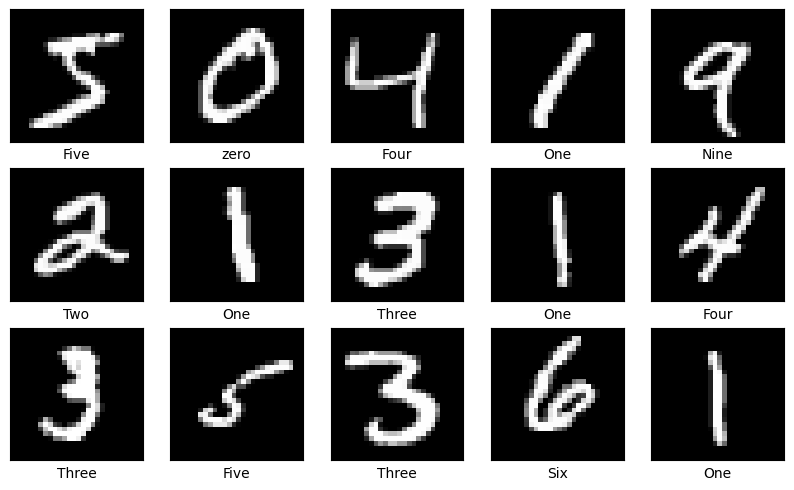

In [5]:
# Visuaizing the digits
col_names = ['zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

plt.figure(figsize=(10,10))
for i in range(15):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.xlabel(col_names[y_train_digit[i]])
  plt.imshow(x_train_digit[i], cmap='grey')
plt.show()


In [6]:
x_train_digit.shape

(60000, 28, 28)

In [7]:
x_test_digit.shape

(10000, 28, 28)

In [8]:
# Converting 3D data to 2D
#Input preprocessing
x_train_digit = x_train_digit.reshape(60000,784)
x_test_digit = x_test_digit.reshape(10000,784)

In [9]:
x_train_digit.shape

(60000, 784)

In [10]:
# Preprocessing Output
y_train_digit.shape

(60000,)

In [11]:
y_train_digit = to_categorical(y_train_digit, num_classes=10)
y_test_digit = to_categorical(y_test_digit, num_classes=10)

In [12]:
y_train_digit.shape

(60000, 10)

In [13]:
y_train_digit[5]

array([0., 0., 1., 0., 0., 0., 0., 0., 0., 0.])

In [14]:
#Creating base neural network
model = keras.Sequential([layers.Dense(256,activation = 'relu',input_shape = (784,)),
                          layers.Dense(128,activation = 'relu'),
                          layers.Dense(64,activation = 'relu'),
                          layers.Dense(10,activation = 'softmax')])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Compiling the model
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['Accuracy'])

In [17]:
# Model Training
training = model.fit(x_train_digit,y_train_digit,epochs=10,batch_size=100,validation_data=(x_test_digit,y_test_digit))

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - Accuracy: 0.8638 - loss: 1.4543 - val_Accuracy: 0.9120 - val_loss: 0.3659
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Accuracy: 0.9391 - loss: 0.2391 - val_Accuracy: 0.9412 - val_loss: 0.2444
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Accuracy: 0.9565 - loss: 0.1582 - val_Accuracy: 0.9511 - val_loss: 0.2021
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - Accuracy: 0.9664 - loss: 0.1157 - val_Accuracy: 0.9512 - val_loss: 0.1924
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Accuracy: 0.9712 - loss: 0.0965 - val_Accuracy: 0.9554 - val_loss: 0.1788
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Accuracy: 0.9750 - loss: 0.0819 - val_Accuracy: 0.9548 - val_loss: 0.1905
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Accuracy: 0.9752 - loss: 0.0852 - val_Accuracy: 0.9537 - val_loss: 0.1738
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Accuracy: 0.9798 - loss: 0.0674 - val_Accuracy: 0.

In [18]:
# model prediction
y_predict = model.predict(x_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [19]:
y_predict[1]

array([2.7478129e-09, 3.5047833e-07, 9.9998379e-01, 9.3500876e-06,
       7.1087379e-17, 2.4201208e-10, 8.8754142e-09, 1.0394266e-14,
       6.5034033e-06, 3.5333189e-13], dtype=float32)

In [20]:
#Here we get the index of maximum value in the encoded vector.
y_predicts = np.argmax(y_predict,axis=1)
y_test_digit_eval = np.argmax(y_test_digit,axis=1)

In [21]:
y_predicts

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [22]:
y_test_digit_eval

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [23]:
# Confusion report
con_matrix = confusion_matrix(y_test_digit_eval,y_predicts)
con_matrix

array([[ 963,    0,    0,    0,    0,    1,    6,    6,    1,    3],
       [   0, 1121,    1,    4,    0,    1,    1,    3,    3,    1],
       [  14,    2,  959,   19,    7,    1,    2,   15,   12,    1],
       [   0,    0,    2,  987,    0,    5,    0,    6,    2,    8],
       [   1,    0,    0,    1,  962,    0,    5,    2,    1,   10],
       [   3,    0,    0,   22,    2,  847,    6,    2,    4,    6],
       [   9,    2,    0,    1,    9,    4,  932,    0,    1,    0],
       [   0,    2,    4,    7,    6,    0,    1,  999,    2,    7],
       [   9,    1,    1,   14,   14,    6,    4,    2,  918,    5],
       [   2,    2,    0,    4,   28,    4,    0,    7,    0,  962]])

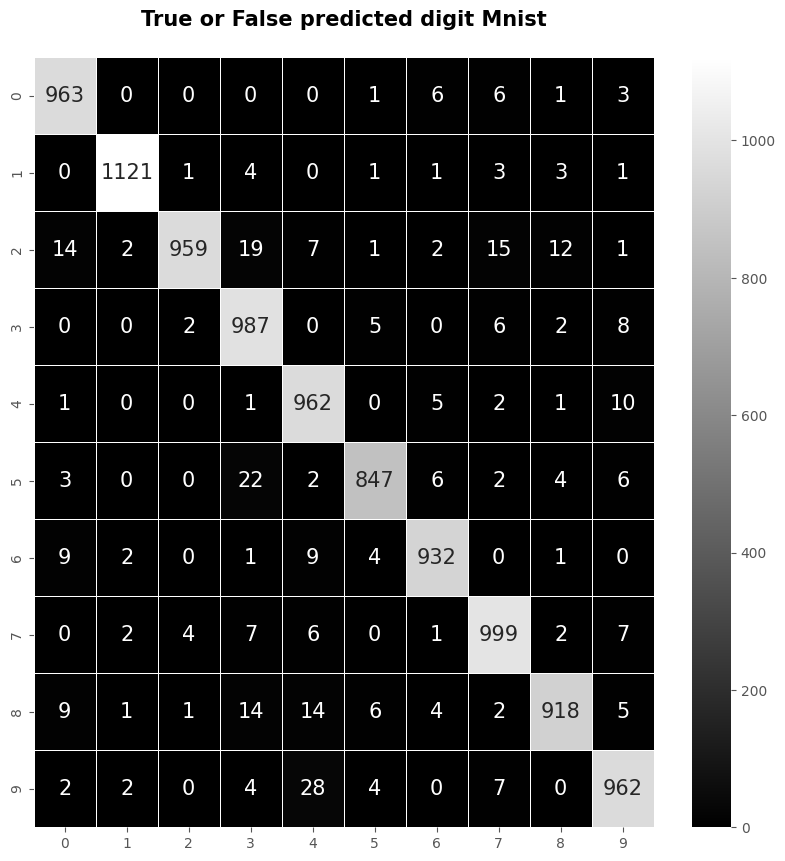

In [24]:
plt.style.use('ggplot')
plt.figure(figsize=(10,10))
sns.heatmap(con_matrix,annot=True,annot_kws={'size':15},linewidths=0.5,fmt='d',cmap='gray')
plt.title('True or False predicted digit Mnist\n', fontweight='bold',fontsize=15)
plt.show()

In [25]:
# Classifiscation report
from sklearn.metrics import classification_report
print(classification_report(y_test_digit_eval,y_predicts))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       980
           1       0.99      0.99      0.99      1135
           2       0.99      0.93      0.96      1032
           3       0.93      0.98      0.95      1010
           4       0.94      0.98      0.96       982
           5       0.97      0.95      0.96       892
           6       0.97      0.97      0.97       958
           7       0.96      0.97      0.97      1028
           8       0.97      0.94      0.96       974
           9       0.96      0.95      0.96      1009

    accuracy                           0.96     10000
   macro avg       0.97      0.96      0.96     10000
weighted avg       0.97      0.96      0.97     10000



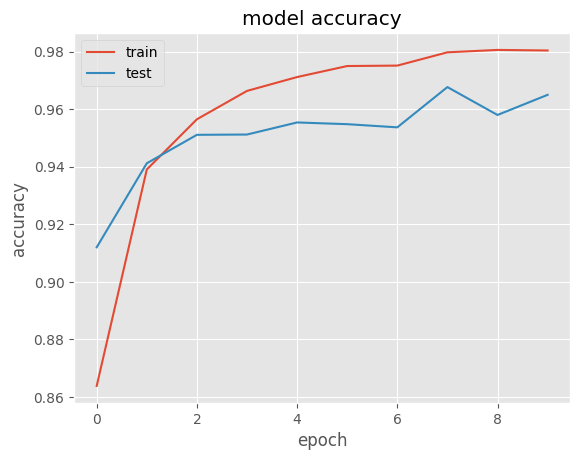

In [26]:
#summarize history for accuracy
plt.plot(training.history['Accuracy'])
plt.plot(training.history['val_Accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'],loc='best')
plt.show()

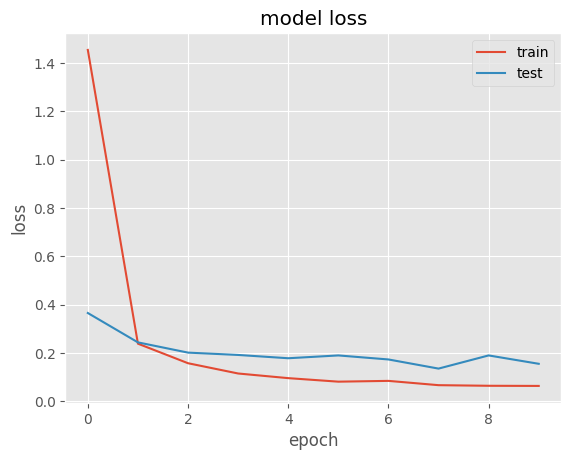

In [27]:
#summarize history for loss
plt.plot(training.history['loss'])
plt.plot(training.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','test'],loc='best')
plt.show()

In [28]:
#single image checking
y_predict_single = model.predict(x_test_digit[[1]])
y_predict_single

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 573ms/step


array([[2.74782352e-09, 3.50478331e-07, 9.99983788e-01, 9.35006938e-06,
        7.10873791e-17, 2.42012521e-10, 8.87539642e-09, 1.03943055e-14,
        6.50340326e-06, 3.53333275e-13]], dtype=float32)

In [29]:
y_predict_single = np.argmax(y_predict_single,axis=1)
y_predict_single

array([2])

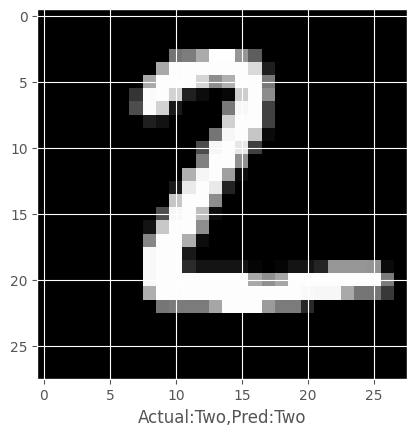

In [30]:
#Names of numbers in the dataset  in order
col_names = ['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']
#visualization the digits
plt.imshow(x_test_digit[1].reshape(28,28),cmap='gray')
plt.xlabel("Actual:{},Pred:{}".format(col_names[y_test_digit_eval[1]],col_names[y_predict_single[0]]))
plt.show()